# A 여름 휴가 절정 주간

입력 변수 `is_vacation_peak`(노션 분석 설계 8.2)의 날짜를 정한다.
휴가철에는 교통량이 줄어 날씨와 상관없이 빨라지므로, 날씨 효과와 섞이지 않게 따로 표시한다.

- 기준은 학습 기간만 본다: 여름 2023, 2024, 2025 (평가 시즌 2026은 열지 않음)
- 맑은 평일(event_id, impact 없음)만, 실제 통행시간 ÷ 시즌 전체 평소값(B 정답용)
- 입력용 평소값(최근 28일)은 휴가철에 같이 내려가서 차이가 묻히므로 쓰지 않는다

결론: 7/21~8/15 (11/25 팀 확정)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

def find_project_root(start=None):
    """지금 폴더에서 위로 올라가며 README.md와 .git이 있는 저장소 루트를 찾는다."""
    current = Path(start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'README.md').is_file() and (candidate / '.git').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트를 찾지 못했습니다.')

ROOT = find_project_root()
ROAD = ROOT / 'data' / 'derived' / 'topis_weather' / 'commute_20261122_v04.parquet'
SUMMERS = ['2023_summer', '2024_summer', '2025_summer']
PEAK = ('07-21', '08-15')

v = pd.read_parquet(ROAD)
v = v[v['season'].isin(SUMMERS)].copy()
v['date'] = pd.to_datetime(v['date'])
v['weekday'] = v['date'].dt.weekday
base = pd.read_csv(ROOT / 'data/shared/train_dev/baseline_train_dev.csv', encoding='utf-8-sig')
v = v.merge(base[['season', 'road_id', 'direction', 'weekday', 'hour', 'baseline_travel_time_s']],
            on=['season', 'road_id', 'direction', 'weekday', 'hour'])
v['ratio'] = v['travel_time_seconds'] / v['baseline_travel_time_s']
clear = v[v['event_id'].isna() & v['impact'].isna()]
len(v), len(clear)

(254700, 206100)

## 1. 주별 변화

날짜마다 도로 180개의 비율 중앙값을 내고, 주(월요일 날짜) 단위로 다시 중앙값을 낸다.

In [2]:
def weekly(hours):
    day = clear[clear['hour'].isin(hours)].groupby('date')['ratio'].median().rename('ratio').reset_index()
    day['year'] = day['date'].dt.year
    day['week'] = (day['date'] - pd.to_timedelta(day['date'].dt.weekday, unit='D')).dt.strftime('%m-%d')
    wk = day.groupby(['week', 'year'])['ratio'].median().unstack()
    wk['3년 평균'] = wk.mean(axis=1)
    return day, wk.loc['07-01':'08-31'].round(3)


day_am, wk_am = weekly([8, 9])
wk_am

year,2023,2024,2025,3년 평균
week,,,,
07-01,NaN,0.999,NaN,0.999
07-03,1.001,NaN,NaN,1.001
07-07,NaN,NaN,1.006,1.006
07-08,NaN,0.995,NaN,0.995
07-10,0.995,NaN,NaN,0.995
07-14,NaN,NaN,1.001,1.001
07-15,NaN,1.000,NaN,1.000
07-17,0.996,NaN,NaN,0.996
07-21,NaN,NaN,0.985,0.985


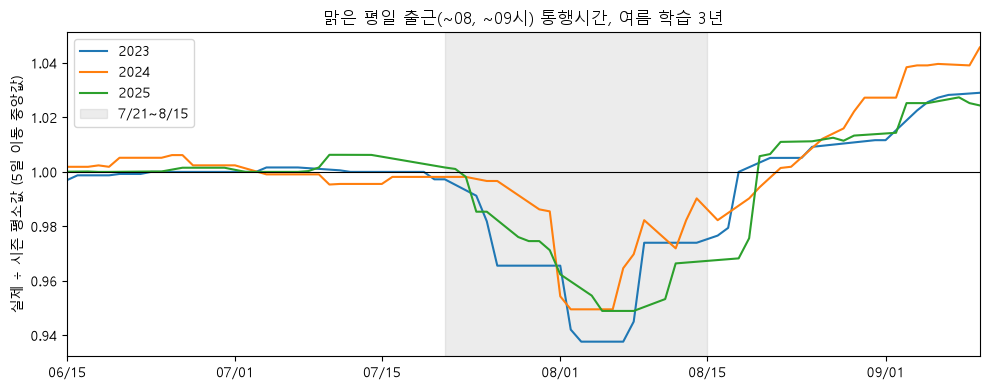

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
for y, g in day_am.groupby('year'):
    g = g.set_index(g['date'].dt.strftime('%m-%d'))['ratio'].rolling(5, min_periods=3).median()
    ax.plot(pd.to_datetime('2000-' + g.index), g.values, label=str(y))
ax.axvspan(pd.Timestamp('2000-' + PEAK[0]), pd.Timestamp('2000-' + PEAK[1]), color='grey', alpha=0.15, label='7/21~8/15')
ax.axhline(1, color='black', lw=0.8)
ax.set_xlim(pd.Timestamp('2000-06-15'), pd.Timestamp('2000-09-10'))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%d'))
ax.set_ylabel('실제 ÷ 시즌 평소값 (5일 이동 중앙값)')
ax.set_title('맑은 평일 출근(~08, ~09시) 통행시간, 여름 학습 3년')
ax.legend()
plt.tight_layout()

7월 셋째 주부터 빨라지기 시작해 7월 말~8월 초가 가장 빠르고(평소의 0.94~0.96배), 8월 중순에 원래대로 돌아온다. 3년 모두 같은 모양이다.

## 2. 기간 후보 비교

In [4]:
am = day_am.set_index('date')['ratio']
md = am.index.strftime('%m-%d')


def gap(a, b, s=am, m=md):
    inside, outside = s[(m >= a) & (m <= b)], s[(m < a) | (m > b)]
    return round((inside.median() / outside.median() - 1) * 100, 1), len(inside)


rows = []
for a, b in [('07-21', '08-15'), ('07-24', '08-11'), ('07-28', '08-08'), ('07-14', '08-22')]:
    pct, n = gap(a, b)
    rows.append({'기간': f'{a}~{b}', '안 날짜 수': n, '안 vs 밖 (%)': pct})
pd.DataFrame(rows)

,기간,안 날짜 수,안 vs 밖 (%)
0,07-21~08-15,46,-3.3
1,07-24~08-11,36,-3.6
2,07-28~08-08,25,-4.6
3,07-14~08-22,67,-2.5


In [5]:
yearly = []
for y in [2023, 2024, 2025]:
    s = am[am.index.year == y]
    yearly.append({'연도': y, '7/21~8/15 안 vs 밖 (%)': gap(*PEAK, s=s, m=s.index.strftime('%m-%d'))[0]})
pd.DataFrame(yearly)

,연도,7/21~8/15 안 vs 밖 (%)
0,2023,-3.7
1,2024,-1.9
2,2025,-3.5


7/21~8/15 안이 밖보다 3.3% 빠르고, 해마다 -3.7%, -1.9%, -3.5%로 3년 모두 같은 방향이다.
7/28~8/8로 좁히면 -4.6%로 커지지만 시작, 끝 주가 빠지므로 7/21~8/15로 정한다.

## 3. 퇴근은 효과가 약하다

In [6]:
day_pm, wk_pm = weekly([18, 19, 20])
wk_pm

year,2023,2024,2025,3년 평균
week,,,,
07-01,NaN,0.962,NaN,0.962
07-03,1.010,NaN,NaN,1.010
07-07,NaN,NaN,1.016,1.016
07-08,NaN,0.989,NaN,0.989
07-10,0.992,NaN,NaN,0.992
07-14,NaN,NaN,0.989,0.989
07-15,NaN,1.017,NaN,1.017
07-17,0.998,NaN,NaN,0.998
07-21,NaN,NaN,1.004,1.004


퇴근(~18, ~19, ~20시)은 7월 말~8월 초 한두 주만 조금 빠르고 해마다 들쭉날쭉하다. 휴가철 효과는 주로 출근길이다.
모델에는 `is_vacation_peak` 하나만 넣고, 출근, 퇴근 차이는 목표 시각 변수와 함께 모델이 나눠 배운다.